# Running the MolCurator agent

The agent curates a benchmark set of molecules whose property lies in a target window. It works in rounds;
each round it:

1. **generates** candidates from the best molecules so far (STONED SELFIES mutations of the seeds at first)
2. **predicts** the property with xTB for a random sample of them (`predict.n_xtb`)
3. **trains** an ML model on every xTB value so far (once there are `train.min_examples`), and scores the rest
4. **screens** the candidates against the target window (plus a margin)
5. with QM on only: sends the best candidates to **QM** (VALIDATE)
6. **curates** the hits into `dataset.csv`

It stops when a budget is reached: `target_dataset_size`, `max_rounds`, `max_qm_calls` or `max_wall_time`.

This notebook runs one small round with the real tools, then looks at the results. It needs the setup from
the README (`scripts/setup.sh`), including xTB. Set `USE_FAKE_TOOLS = True` below to run in a second with
fake chemistry instead. The same run from a terminal is `molcurator run -c configs/homo_lumo.yaml`.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display
from rich.text import Text

from molcurator.agent.progress import progress_text
from molcurator.agent.runner import run_agent
from molcurator.config import RunConfig, load_config

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # the repository
USE_FAKE_TOOLS = False  # True: fake chemistry from tests/agent/fakes.py, no xTB needed

## 1. The run config

A run is described by one YAML file in `configs/`. Anything it leaves out uses the defaults in
`src/molcurator/config.py`.

In [2]:
config = load_config(ROOT / "configs" / "homo_lumo.yaml")
print("target:   ", config.target)
print("seeds:    ", config.seeds)
print("budget:   ", config.budget)
print("decisions:", config.decisions, "| QM on:", config.qm.enabled)

target:    name='homo_lumo_gap' min=4.0 max=4.5 units='eV'
seeds:     ['c1csc(-c2cccs2)c1']
budget:    max_rounds=5 max_qm_calls=20 target_dataset_size=10 max_wall_time=3600
decisions: rules | QM on: False


For a quick demo, shrink it to one round of 300 candidates with xTB on 100 of them, and let TRAIN start at
50 xTB values so the round also trains a model and scores the other 200 with it. Overrides go through
`RunConfig.model_validate`, so a mistyped setting fails here instead of being ignored.

In [3]:
data = config.model_dump()
data["generation"]["defaults"]["n_candidates"] = 300
data["predict"]["n_xtb"] = 100
data["train"]["min_examples"] = 50
data["budget"].update(max_rounds=1, target_dataset_size=1000)
config = RunConfig.model_validate(data)

## 2. Run the agent

`run_agent` creates a new run folder in `data/runs/<run_id>/` and runs the graph to the end. `on_event` gets
every trace event as it is written; here it prints the same progress lines as the CLI. With real xTB this
takes about two minutes.

In [4]:
tools = None  # None: the real tools (molcurator.tools)
if USE_FAKE_TOOLS:
    import sys
    sys.path.insert(0, str(ROOT))
    from molcurator.agent.toolset import Toolset
    from tests.agent.fakes import FakeTools
    tools = Toolset.from_object(FakeTools())

state = run_agent(config, tools=tools, runs_root=ROOT / "data" / "runs",
                  on_event=lambda event: print(Text.from_markup(progress_text(event)).plain))
run_dir = Path(state["run_dir"])
print("\nRun folder:", run_dir.relative_to(ROOT))

Run 20261022-144930-b541 started


r1 plan_round Rule: repeat the previous settings with the best parents so far. (0.0 s)


r1 generate generated 300 (4.1 s)


r1 predict predicted 93 · failed 7 (72.3 s)


r1 train trained on 93 · test MAE 0.31 (mean baseline 0.41) (3.5 s)


r1 ml_predict ml_predicted 199 · failed 1 (0.2 s)
r1 screen screened_out 153 · screened_in 139 (0.0 s)
r1 curate curated 11 (0.0 s)
r1 close_round generated 300 · xTB 100 · ML 199 · screened in 139 · hits 11 (0.0 s)
r1 continue_or_stop max_rounds (0.0 s)
r1 write_summary max_rounds (0.0 s)

Run folder: data/runs/20261022-144930-b541


## 3. Results

The final state says why the run stopped; `round_stats` has one row of counts per round.

In [5]:
print("stopped because:", state["stop_reason"], "| dataset size:", state["dataset_size"])
pd.DataFrame(state["round_stats"]).set_index("round")

stopped because: max_rounds | dataset size: 11


,generated,duplicates,xtb_runs,ml_predicted,unscored,failed,screened_in,selected,qm_calls,hits
round,,,,,,,,,,
1,300,0,100,199,0,8,139,0,0,11


`dataset.csv` holds the curated molecules, with a value at every level each one has (`ml`, `xtb`, `qm`)
and where it came from. Molecules with only an ML value are also listed in `dataset_ml_only.csv`.

In [6]:
dataset = pd.read_csv(run_dir / "dataset.csv")
dataset[["id", "smiles", "ml", "xtb", "qm", "validated", "parent", "round"]]

,id,smiles,ml,xtb,qm,validated,parent,round
0,r1-c095,C=C1C=C(c2ccc[nH]2)SS1,4.268767,NaN,NaN,False,c1csc(-c2cccs2)c1,1
1,r1-c139,C=C1C=C(c2cccs2)SO1,NaN,4.499502,NaN,False,c1csc(-c2cccs2)c1,1
2,r1-c144,C=C1C=C(c2cccs2)SN1,NaN,4.351079,NaN,False,c1csc(-c2cccs2)c1,1
3,r1-c146,C=CSC(=C)c1ccc[nH]1,4.446998,NaN,NaN,False,c1csc(-c2cccs2)c1,1
4,r1-c207,C=CSC(=CN)c1ccc[nH]1,4.473892,NaN,NaN,False,c1csc(-c2cccs2)c1,1
5,r1-c226,C1=Cc2cccc(c2)S1,4.450216,NaN,NaN,False,c1csc(-c2cccs2)c1,1
6,r1-c228,C=C1C=C(Nc2ccc[nH]2)S1,4.303869,NaN,NaN,False,c1csc(-c2cccs2)c1,1
7,r1-c244,C1=CC(c2ccns2)=C1,4.275314,NaN,NaN,False,c1csc(-c2cccs2)c1,1
8,r1-c254,C#Cc1cc2ccc1s2,4.000383,NaN,NaN,False,c1csc(-c2cccs2)c1,1
9,r1-c280,SC=C1C=C(c2cccs2)SS1,NaN,4.434509,NaN,False,c1csc(-c2cccs2)c1,1


`summary.md` is a short report of the run (written by the rules here, or by Claude with `decisions: llm`).

In [7]:
display(Markdown((run_dir / "summary.md").read_text()))

# Run 20261022-144930-b541

Target: homo_lumo_gap (min 4.0, max 4.5 eV).

Rounds: 1. Generated: 300. QM calculations: 0. Confirmed hits: 11 (dataset size 11).

Stopped because: max_rounds.

ML-only molecules: 8 (dataset_ml_only.csv)


## 4. The curated molecules

Each one with its best available value: QM if it has one, else xTB, else ML.

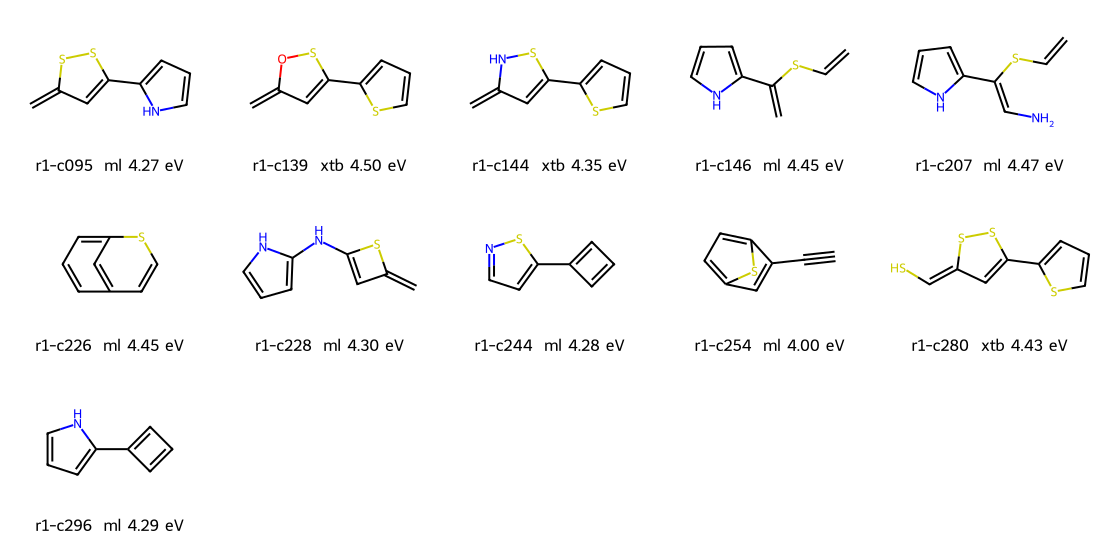

In [8]:
from rdkit import Chem
from rdkit.Chem import Draw

def best_value(row):
    level = next(k for k in ("qm", "xtb", "ml") if pd.notna(row[k]))
    return f"{row['id']}  {level} {row[level]:.2f} eV"

shown = dataset.head(15)
Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in shown["smiles"]], molsPerRow=5, subImgSize=(220, 180),
                     legends=[best_value(r) for _, r in shown.iterrows()])

## 5. Next steps

- **Every step is traced** in `traces/trace.jsonl`, one JSON line per step (format: `docs/trace-format.md`).
  Check a run's trajectory with
  `python scripts/evaluate_trajectory.py data/runs/<run_id>/traces/trace.jsonl --out report.json`.
- **Resume** an interrupted run (e.g. Ctrl-C) from its last finished step:
  `molcurator run --resume <run_id>`; the state after every step is in `checkpoint.sqlite`.
- **Let Claude decide** (plan rounds, continue or stop, write the summary): set `decisions: llm`. It needs
  `ANTHROPIC_API_KEY` in `.env` and costs a few cents per run; the rules take over whenever an answer is
  invalid or late. `scripts/check_llm_decider.py` is a cheap live check.
- **Validate hits with QM**: add a `qm:` section naming the method (commented out in
  `configs/homo_lumo.yaml`). QM is slow, so `budget.max_qm_calls` caps it, spread evenly over the rounds.